# Project 3: Can a PINN handle a shock hitting a material interface?

MAE 598 Design Optimization, Project 3 (PINN/PINO in the Field)
Team: [names]
Researcher: Prof. Marcus Herrmann, SEMTE, ASU (multiphase flow and interface-capturing methods)

This notebook is the report. Every table and figure in section 4 is produced by the code cells below, and section 7 explains how to rerun everything. The solvers live in `src/` and are imported here, so the notebook stays readable.

---

In [1]:
# Setup: run from the repo root (locally or on Colab).
import os, sys, json, glob, time, runpy, contextlib, io
if not os.path.isdir("src") and not os.path.isfile("pinn.py"):
    # On Colab: clone the repo first (replace with your team's URL)
    !git clone https://github.com/[team]/[repo].git repo
    os.chdir("repo")
if os.path.isdir("src"):
    os.chdir("src")          # the scripts read/write ../results and ../figures
sys.path.insert(0, os.getcwd())

import numpy as np
import torch
from IPython.display import Image, Markdown, display

print("numpy", np.__version__, "| torch", torch.__version__, "| cwd", os.getcwd())

# Switches
RUN_ALL_PINNS = False   # True: retrain every PINN in this report (~5 CPU-hours). False: load results/runs/
RERUN_ONE     = True    # retrain one case from scratch and check it matches the stored numbers (~10 min, CPU)

def table(header, rows):
    """Render a list of rows as a Markdown table."""
    out = "| " + " | ".join(header) + " |\n|" + "---|" * len(header) + "\n"
    for r in rows:
        out += "| " + " | ".join(r) + " |\n"
    display(Markdown(out))

def f3(x):
    return "" if x is None else f"{x:.3f}"

numpy 2.5.3 | torch 2.14.1+cu130 | cwd /home/claude/pinn-shock-interface/src


## 1. Outreach log

| When | What happened |
|---|---|
| [date] | Picked Prof. Herrmann from the course candidate list. His group works on interface-capturing methods (level set, volume of fluid) for atomization, and his row suggested level-set advection as a minimal case, which looked like a good fit for a PINN study. Reserved him on the participation sheet. Backup: [backup researcher]. |
| [date] | Emailed him with five questions about a 1-D level-set advection case (velocity field, initial interface, BC/IC, expected PINN problems, references and validation). |
| [date] | He replied by email. No live meeting; the conversation happened in writing. His reply is summarised in section 2 and it changed our plan completely. |
| [date] | Sent him the problem brief (section 2) and asked for corrections. [Add his reply here, or "no reply yet".] |
| [date] | Sent the recommendation memo (section 5). [Add his reply if any.] |

Our original questions assumed we would do 1-D level-set advection. The most useful thing we got out of the exchange was being told, politely, that this case is not worth doing.

## 2. Problem brief

**What Prof. Herrmann works on.** His group simulates multiphase flows where a liquid and a gas share a sharp, moving interface, with the main application being atomization: a liquid jet or sheet breaking up into ligaments and droplets. This matters wherever fuel or another liquid gets sprayed: gas turbine and rocket combustors, diesel injectors, spray coating, and so on. Drop sizes coming out of primary breakup set how fast the fuel evaporates and burns, and experiments struggle to see inside the dense spray near the nozzle, which is why simulation carries so much of the load.

**The equations.** The flow is Navier–Stokes (incompressible in the low-Mach limit, compressible when shocks or bubble collapse are involved). The interface is captured on a grid by an extra scalar transported with the flow, either a level set $\phi$ (the interface is the zero contour) or a volume fraction $\alpha$ (VOF):

$$\frac{\partial \phi}{\partial t} + \mathbf{u}\cdot\nabla\phi = 0, \qquad \frac{\partial \alpha}{\partial t} + \nabla\cdot(\alpha\mathbf{u}) = \alpha\,\nabla\cdot\mathbf{u}.$$

Density and viscosity jump across the interface (about 1000:1 in density for water and air), and surface tension acts there as a singular force. His published work includes the refined level set grid method, where the level set lives on its own finer grid so the interface stays sharp on a coarser flow grid (Herrmann, 2008).

**What makes it hard.** The interface is a discontinuity in density, so anything that smears it also smears mass, momentum and the surface tension force. Large density ratios make the pressure equation stiff, and in compressible cases shocks interact with the interface. On the VOF side, a hard step is geometric interface reconstruction: from the volume fractions in each cell, rebuild an interface that is consistent with them and physically sensible.

**What he told us about our original idea.** Paraphrasing his reply:

- 1-D multiphase flow in the incompressible limit is "quite trivial". Even with phase change, analytical solutions exist. A 1-D case is only interesting if it is fully compressible; otherwise you need at least 2-D.
- Good compressible 1-D cases: a planar shock interacting with a drop, or (spherical) bubble collapse. A good 2-D incompressible case: Rayleigh–Taylor instability (heavy liquid over gas, sinusoidal perturbation, gravity, mushroom-shaped rollup).
- Boundary conditions are straightforward in both.
- He has not used PINNs for this, so he could not say what goes wrong.
- Comparing against an analytical or numerical solution counts as *verification*; *validation* would need experimental data.
- He also suggested a problem where PINNs "either may work or will fail spectacularly": the inverse problem behind VOF interface reconstruction. The forward direction (geometry to cell volume fractions) is easy, so training data is cheap.

**Current solver and cost.** We did not get a run time or core count for his production solver, and we should have asked. That is a real gap in this brief. From the literature, primary atomization DNS of this type runs on large parallel machines, but we do not have his numbers.

**Prior PINN/PINO attempts.** None in his group, as far as he told us. That puts us in "fresh territory": no failure was reported to us, so for Path B we picked the failure we expected from the triage guide (sharp fronts and interfaces sit in the "poor fit" column).

**Did the researcher review this brief?** [Yes / not yet, sent on date.]

## 3. Minimal case formulation

**Why this case.** Of his suggestions, the planar shock/drop interaction is the one we can do properly in 1-D on a laptop, and it has an exact solution we can trust as a reference. Rayleigh–Taylor needs 2-D Navier–Stokes with a level set or VOF coupled in, which is a big step up both for the PINN and for a fair baseline. The VOF reconstruction problem is interesting, but it is not really a PDE problem, so we kept it for the memo as a follow-up.

**Simplifications.**

1. *Drop → single planar interface.* In 1-D a "drop" is a slab with two interfaces. We keep one interface and start the clock at the moment the incident shock reaches it. The waves that make the problem hard are all still there: a transmitted shock into the heavy fluid, a reflected wave back into the light fluid, and the interface itself moving as a contact discontinuity.
2. *Both fluids are ideal gases with $\gamma = 1.4$.* A real liquid needs a stiffened-gas equation of state, and a different $\gamma$ on each side brings in the well-known spurious pressure oscillations at the interface in conservative schemes. Keeping one $\gamma$ means the only thing separating the two fluids is a density jump, so the knob controls exactly one thing.
3. *Inviscid, no surface tension.* For a planar interface the curvature is zero, so surface tension does nothing in this 1-D geometry anyway.
4. *No interface marker field.* With one $\gamma$ the level set would be a passive scalar, so we track the interface through the density jump.

**Governing equations** (1-D Euler, nondimensionalised by the pre-shock light-gas density and pressure):

$$\frac{\partial}{\partial t}\begin{pmatrix}\rho\\ \rho u\\ E\end{pmatrix} + \frac{\partial}{\partial x}\begin{pmatrix}\rho u\\ \rho u^2 + p\\ u(E+p)\end{pmatrix} = 0, \qquad E = \frac{p}{\gamma-1} + \tfrac12\rho u^2,$$

on $x \in [0,1]$, $t \in [0, T]$ with $T = 0.3$.

**Initial condition.** The interface sits at $x_0 = 0.4$, with a Mach 1.5 shock in the light gas just arriving at it:

$$(\rho, u, p)(x, 0) = \begin{cases} (1.862,\ 0.822,\ 2.458) & x < x_0 \quad \text{(shocked light gas, from Rankine–Hugoniot)}\\ (r,\ 0,\ 1) & x > x_0 \quad \text{(heavy gas at rest)}\end{cases}$$

**Boundary conditions.** Dirichlet, equal to the left and right initial states. We picked $x_0$ and $T$ so that no wave reaches either boundary before $t = T$ for any knob value (the fastest left-going wave reaches $x \approx 0.10$, the fastest right-going one $x \approx 0.93$), so this is exact and not an approximation.

**Difficulty knob: the density ratio $r = \rho_{\text{heavy}}/\rho_{\text{light}}$**, swept over $r \in \{1, 3, 10, 30, 100\}$. At $r = 1$ the interface is invisible and the solution is just the incident shock moving on, so $r = 1$ is our "shock only" control. As $r$ grows, the reflected shock gets stronger, the transmitted shock and interface slow down, and a thin, very dense layer of shocked heavy gas forms between them (at $r = 100$ it is about 0.03 wide with $\rho \approx 270$). For reference, water/air would be $r \approx 1000$.

In [2]:
# Wave pattern for each knob value, straight from the exact Riemann solver (src/riemann.py)
from riemann import wave_summary, post_shock_state, X0, T_END
rho2, u2, p2 = post_shock_state()
print(f"post-shock light gas (Mach 1.5): rho = {rho2:.3f}, u = {u2:.3f}, p = {p2:.3f}")
rows = []
for r in [1, 3, 10, 30, 100]:
    w = wave_summary(r)
    refl = "none (shock passes through)" if r == 1 else w["reflected"]
    rows.append([str(r), refl, f"{w['interface_speed']:.2f}", f"{w['transmitted_speed']:.2f}", f"{w['p_star']:.2f}"])
table(["$r$", "reflected wave", "interface speed", "transmitted shock speed", "$p^*$"], rows)
w100, w1 = wave_summary(100), wave_summary(1)
print(f"fastest left wave reaches x = {X0 + w100['reflected_speed']*T_END:.3f}, "
      f"fastest right wave reaches x = {X0 + w1['transmitted_speed']*T_END:.3f} by t = T")

post-shock light gas (Mach 1.5): rho = 1.862, u = 0.822, p = 2.458


| $r$ | reflected wave | interface speed | transmitted shock speed | $p^*$ |
|---|---|---|---|---|
| 1 | none (shock passes through) | 0.82 | 1.77 | 2.46 |
| 3 | shock | 0.60 | 1.14 | 3.06 |
| 10 | shock | 0.40 | 0.68 | 3.74 |
| 30 | shock | 0.26 | 0.42 | 4.28 |
| 100 | shock | 0.15 | 0.24 | 4.72 |


fastest left wave reaches x = 0.101, fastest right wave reaches x = 0.932 by t = T


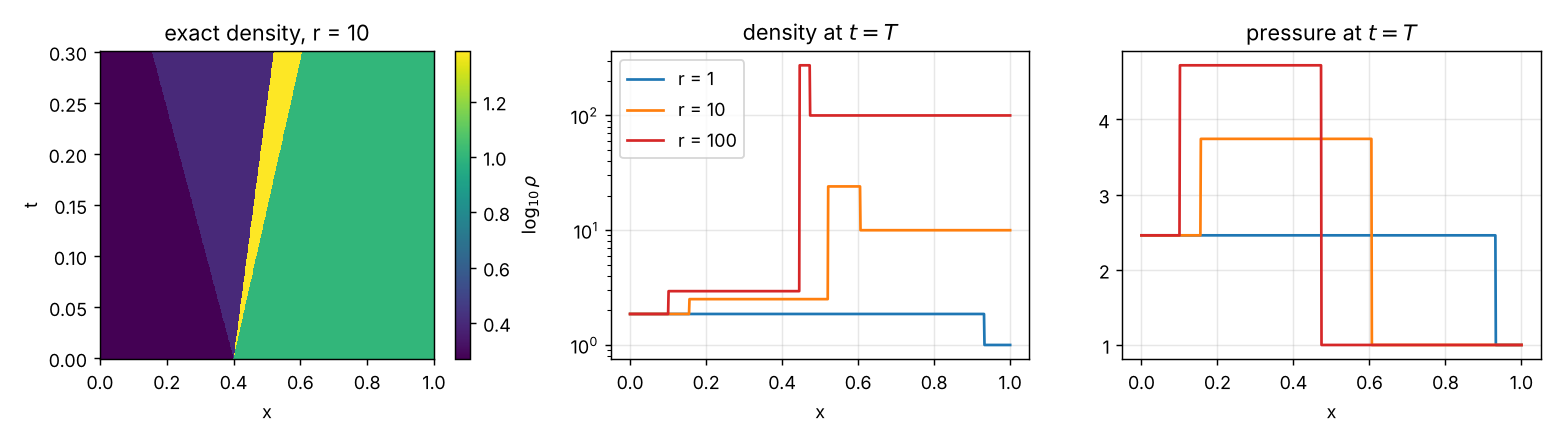

In [3]:
import make_figures as mf
mf.fig_problem()
display(Image("../figures/fig1_problem.png"))

*Left: exact density in $(x,t)$ for $r=10$; the reflected shock, the interface and the transmitted shock all start at $(x_0, 0)$. Middle and right: density and pressure at $t=T$ for three knob values. Note the thin, dense layer between the interface and the transmitted shock.*

**Reference solution.** The exact Riemann solution (Toro, ch. 4), computed in `src/riemann.py`. We checked it two ways: the $r=1$ case reproduces the incident shock speed $W_s = 1.5\sqrt{1.4} = 1.775$, and the finite-volume solver converges to it for every $r$ (section 4, P1).

**Path.** B (diagnosis), plus a Path C attempt.

## 4. Experiments

All PINN runs use the same network and budget unless stated: 4 hidden layers of 64 tanh units, inputs $(x,t)$ scaled to $[-1,1]$, outputs scaled by the largest initial value of each variable, 4000 random collocation points, 400 IC points, 200 BC points per side, Adam for 10,000 iterations with the learning rate decaying from $10^{-3}$ to $10^{-4}$, seed 0. Errors are relative $L_2$ errors against the exact solution on a $201 \times 61$ grid covering all of $(x,t)$, so early and late times count equally.

In [4]:
# The full list of PINN runs in this report. With RUN_ALL_PINNS = False we only load what is stored.
from pinn import Config, train
from run import EXPERIMENTS

PLAN = ([("vanilla", r, 0) for r in [1, 3, 10, 30, 100]]
        + [(e, r, 0) for e in ["supervised", "normalized", "rad", "visc", "logrho"] for r in [1, 10, 100]]
        + [("causal", r, 0) for r in [10, 100]]
        + [("vanilla", r, 1) for r in [1, 10, 100]])          # second seed

for name, r, seed in PLAN:
    path = f"../results/runs/{name}_r{r:g}_s{seed}.json"
    if RUN_ALL_PINNS or not os.path.exists(path):
        train(Config(name=name, r=r, seed=seed, iters=10000, **EXPERIMENTS[name]), verbose=False)

R = {}
for name, r, seed in PLAN:
    R[(name, r, seed)] = json.load(open(f"../results/runs/{name}_r{r:g}_s{seed}.json"))
print(f"{len(R)} PINN runs available; total training time {sum(v['train_time'] for v in R.values())/3600:.1f} CPU-hours")
EXPERIMENTS

25 PINN runs available; total training time 4.5 CPU-hours


{'vanilla': {},
 'supervised': {'mode': 'supervised'},
 'normalized': {'normalize': True},
 'rad': {'normalize': True, 'adaptive': True},
 'visc': {'normalize': True, 'nu': 0.005, 'nu_final': 0.001},
 'logrho': {'normalize': True, 'logrho': True},
 'causal': {'normalize': True, 'causal': 50.0},
 'fix': {'normalize': True, 'logrho': True, 'nu': 0.005, 'nu_final': 0.001}}

### P1: Baseline

A second-order finite-volume solver (MUSCL with minmod on primitive variables, HLLC flux, SSP-RK2, CFL 0.5) in about 100 lines of NumPy, `src/fv_solver.py`. It is nothing special, which is the point: any CFD group already has something better. The cell below runs it from scratch (about a minute) and measures the error exactly like we measure the PINN: relative $L_2$ error in $\rho$ over the same $201\times61$ space-time grid.

| $r$ | 100 cells | 400 cells | 1600 cells | wall time (100 / 400 / 1600) |
|---|---|---|---|---|
| 1 | 0.030 | 0.016 | 0.008 | 0.05 s / 0.23 s / 1.59 s |
| 3 | 0.108 | 0.064 | 0.037 | 0.09 s / 0.25 s / 1.59 s |
| 10 | 0.168 | 0.101 | 0.060 | 0.05 s / 0.19 s / 1.39 s |
| 30 | 0.191 | 0.116 | 0.069 | 0.06 s / 0.21 s / 1.43 s |
| 100 | 0.195 | 0.122 | 0.074 | 0.07 s / 0.23 s / 1.47 s |


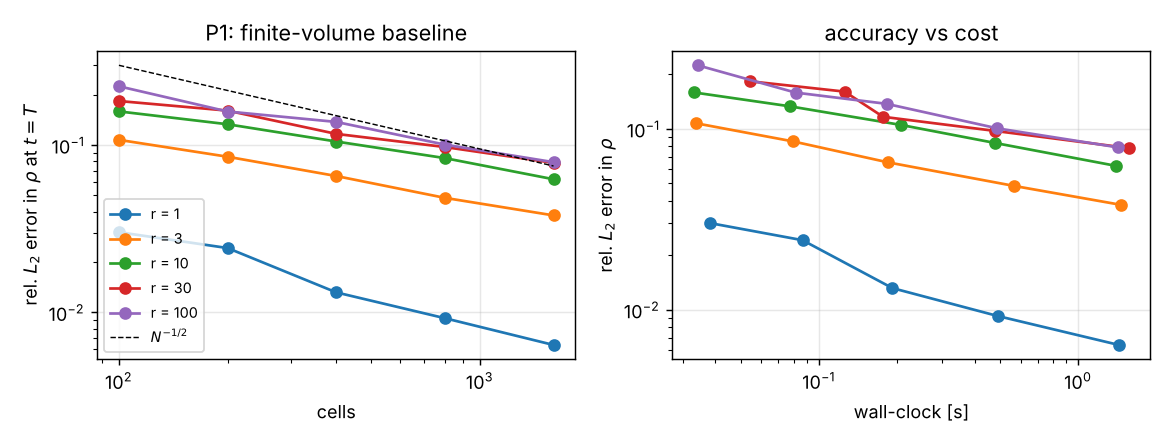

In [5]:
from fv_solver import spacetime_error, solve, rel_l2
from riemann import exact_field

with contextlib.redirect_stdout(io.StringIO()):          # also writes results/fv_baseline*.json for the plots
    runpy.run_path("fv_solver.py", run_name="__main__")
FV = json.load(open("../results/fv_baseline_spacetime.json"))
rows = []
for r in [1, 3, 10, 30, 100]:
    d = FV[str(r)]
    rows.append([str(r)] + [f"{d[n]['err_rho']:.3f}" for n in ["100", "400", "1600"]]
                + [" / ".join(f"{d[n]['wall']:.2f} s" for n in ["100", "400", "1600"])])
table(["$r$", "100 cells", "400 cells", "1600 cells", "wall time (100 / 400 / 1600)"], rows)
mf.fig_baseline()
display(Image("../figures/fig2_baseline.png"))

Two things to note. The error falls roughly like $N^{-1/2}$, which is what you get in $L_2$ for any solution with jumps; it is not a bug in the scheme. And even the FV error grows with $r$, because the interface is a contact discontinuity: unlike a shock, nothing in the physics steepens it back up once the scheme smears it. So the knob makes the problem harder for the conventional method too, just much less dramatically.

The next cell verifies the reference solution independently (`src/check_reference.py`): across every shock in the exact solution the Rankine–Hugoniot jump conditions hold to round-off ($\sim 10^{-14}$), and $u$ and $p$ are continuous across the interface while $\rho$ jumps. The same script recomputes the vanilla $r=10$ PINN error from the saved field (0.362, same as logged).

In [6]:
runpy.run_path("check_reference.py", run_name="__main__");

r=  3: RH residual transmitted 5.3e-15, reflected 8.9e-15; contact: u*=0.6049 both sides, p*=3.0622, rho jumps 2.178 -> 6.413
r= 10: RH residual transmitted 1.8e-15, reflected 3.6e-15; contact: u*=0.4003 both sides, p*=3.7416, rho jumps 2.508 -> 24.072
r=100: RH residual transmitted 2.8e-14, reflected 3.6e-15; contact: u*=0.1536 both sides, p*=4.7201, rho jumps 2.944 -> 273.511
vanilla r=10: recomputed rel. L2 error 0.3620, logged 0.3620


### P2: Loss components

Each loss term is logged separately every 100 iterations (P2); the dashed line is the density error, checked every 1000 iterations.

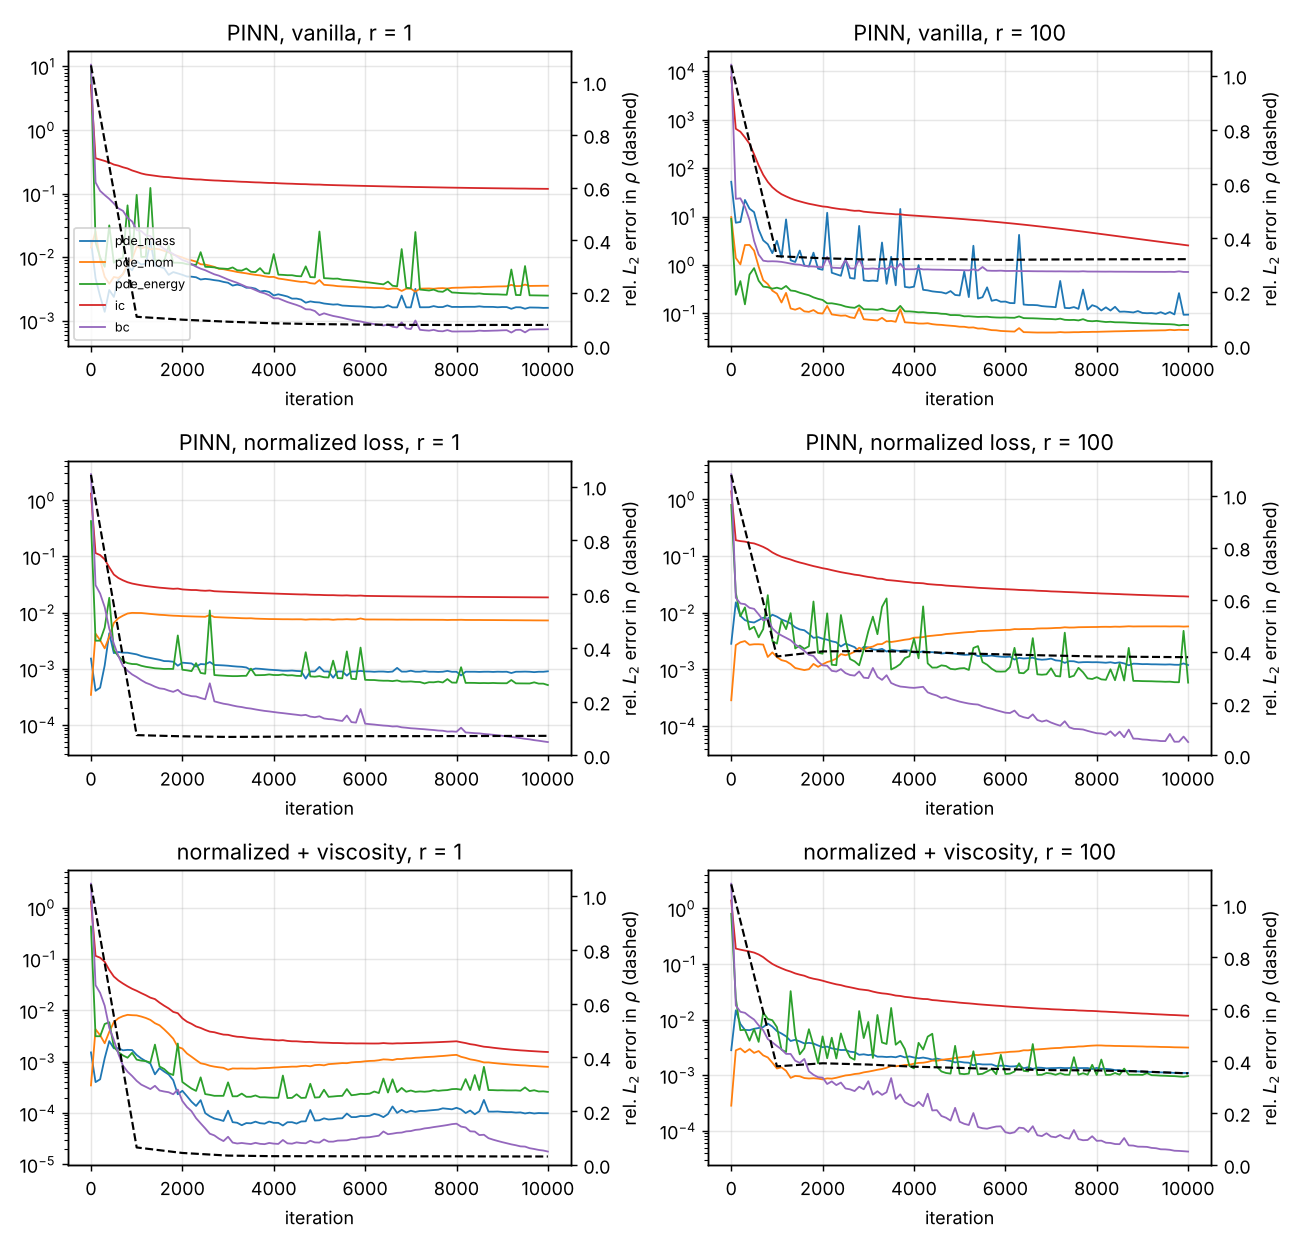

In [7]:
mf.fig_losses(("vanilla", "normalized", "visc"))
display(Image("../figures/fig3_losses.png"))

Top row is the vanilla PINN. At $r = 1$ every loss term goes down nicely and the density error settles at 8% within about 1000 iterations; after that the losses keep shrinking for 9000 more iterations and the error does not move. At $r = 100$ the picture is worse. In raw units the IC and BC terms start around $10^3$–$10^4$ (the heavy gas has $\rho = 100$, so a mismatch in density is a big number), the PDE terms are tiny next to them, and the optimizer spends the run fitting the initial and boundary data. The density error is stuck at 32% from iteration 1000 on.

Middle row: the same thing with every term divided by a typical size for that variable or equation (section "Path B" below). All terms now start within two orders of magnitude of each other. One thing stays the same in every normalized run without viscosity, whatever else we changed (adaptive sampling, $\log\rho$ output, causal weights): the IC loss plateaus somewhere around $1$–$4\times10^{-2}$ and never gets below that. The network does not manage to reproduce the initial jump while also satisfying the PDE right next to it.

Bottom row: normalized loss plus artificial viscosity (Path C attempt). The IC loss now does go down (to $\sim10^{-3}$ at $r=1$), because the viscous problem no longer asks for a true jump.

### P3: Error vs. knob

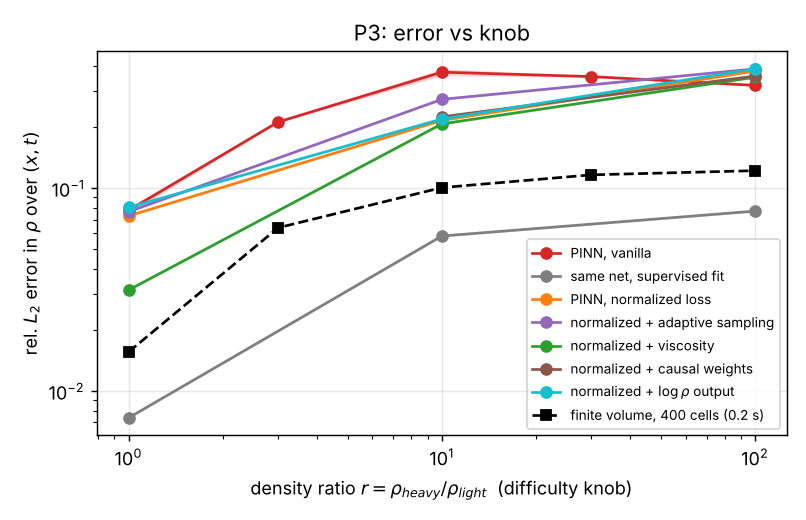

| variant | $r=1$ | $r=3$ | $r=10$ | $r=30$ | $r=100$ |
|---|---|---|---|---|---|
| finite volume, 400 cells (0.2 s) | 0.016 | 0.064 | 0.101 | 0.116 | 0.122 |
| PINN, vanilla | 0.080 | 0.212 | 0.362 | 0.355 | 0.321 |
| same network, supervised fit to exact solution | 0.007 |  | 0.058 |  | 0.077 |
| PINN, normalized loss | 0.073 |  | 0.216 |  | 0.378 |
| normalized + adaptive sampling (RAD) | 0.077 |  | 0.274 |  | 0.388 |
| normalized + $\log\rho$ output | 0.080 |  | 0.219 |  | 0.388 |
| normalized + causal weights |  |  | 0.225 |  | 0.357 |
| normalized + viscosity curriculum | 0.031 |  | 0.208 |  | 0.353 |


In [8]:
mf.fig_knob([n for n in mf.COL])
display(Image("../figures/fig4_knob.png"))

order = ["vanilla", "supervised", "normalized", "rad", "logrho", "causal", "visc"]
names = {"vanilla": "PINN, vanilla", "supervised": "same network, supervised fit to exact solution",
         "normalized": "PINN, normalized loss", "rad": "normalized + adaptive sampling (RAD)",
         "logrho": r"normalized + $\log\rho$ output", "causal": "normalized + causal weights",
         "visc": "normalized + viscosity curriculum"}
knob = [1, 3, 10, 30, 100]
rows = [["finite volume, 400 cells (0.2 s)"] + [f3(FV[str(r)]["400"]["err_rho"]) for r in knob]]
for e in order:
    rows.append([names[e]] + [f3(R[(e, r, 0)]["err_rho"]) if (e, r, 0) in R else "" for r in knob])
table(["variant"] + [f"$r={r}$" for r in knob], rows)

(relative $L_2$ error in $\rho$ over all of $(x,t)$; velocity and pressure errors are in `results/summary.csv`)

To check that one seed is not misleading us, we repeated the vanilla runs at $r = 1, 10, 100$ with a second seed:

In [9]:
table(["$r$", "seed 0", "seed 1"], [[str(r), f3(R[("vanilla", r, 0)]["err_rho"]), f3(R[("vanilla", r, 1)]["err_rho"])] for r in [1, 10, 100]])
mf.table([n for n in mf.COL])        # writes results/summary.csv (all errors and timings)

| $r$ | seed 0 | seed 1 |
|---|---|---|
| 1 | 0.080 | 0.076 |
| 10 | 0.362 | 0.385 |
| 100 | 0.321 | 0.322 |


[('vanilla',
  1,
  0,
  0.07979931756059129,
  0.17470821607478926,
  0.10028827453975533,
  546.297426426,
  0.010626154999999925),
 ('vanilla',
  1,
  1,
  0.07551322117135667,
  0.18265169589634367,
  0.09784299389217861,
  577.7360141289992,
  0.005996839600084058),
 ('vanilla',
  3,
  0,
  0.2119397677619949,
  0.21424984012629814,
  0.14503314187967545,
  556.080548467,
  0.009699966099992708),
 ('vanilla',
  10,
  0,
  0.36197795026357116,
  0.41913090172124506,
  0.2848725012804124,
  544.8994324779999,
  0.010919740200006346),
 ('vanilla',
  10,
  1,
  0.38450999408092357,
  0.4035778331753944,
  0.27048256804326776,
  595.9127490679994,
  0.010952350400111754),
 ('vanilla',
  30,
  0,
  0.35505472310700703,
  0.6382728711374542,
  0.37201379824920605,
  546.7597097370001,
  0.005904738300000645),
 ('vanilla',
  100,
  0,
  0.3210435739672032,
  1.0376997106398165,
  0.43656459899863015,
  530.6843532569999,
  0.005428161700001511),
 ('vanilla',
  100,
  1,
  0.32153962852430

The spread is a few percent, much smaller than the effects we discuss. The plot shows the mean over seeds with the range shaded; the other variants have one seed each.

The vanilla PINN error goes from 8% at $r=1$ to 36% at $r=10$ and then flattens. The flattening is not the PINN getting better. Look at the profiles:

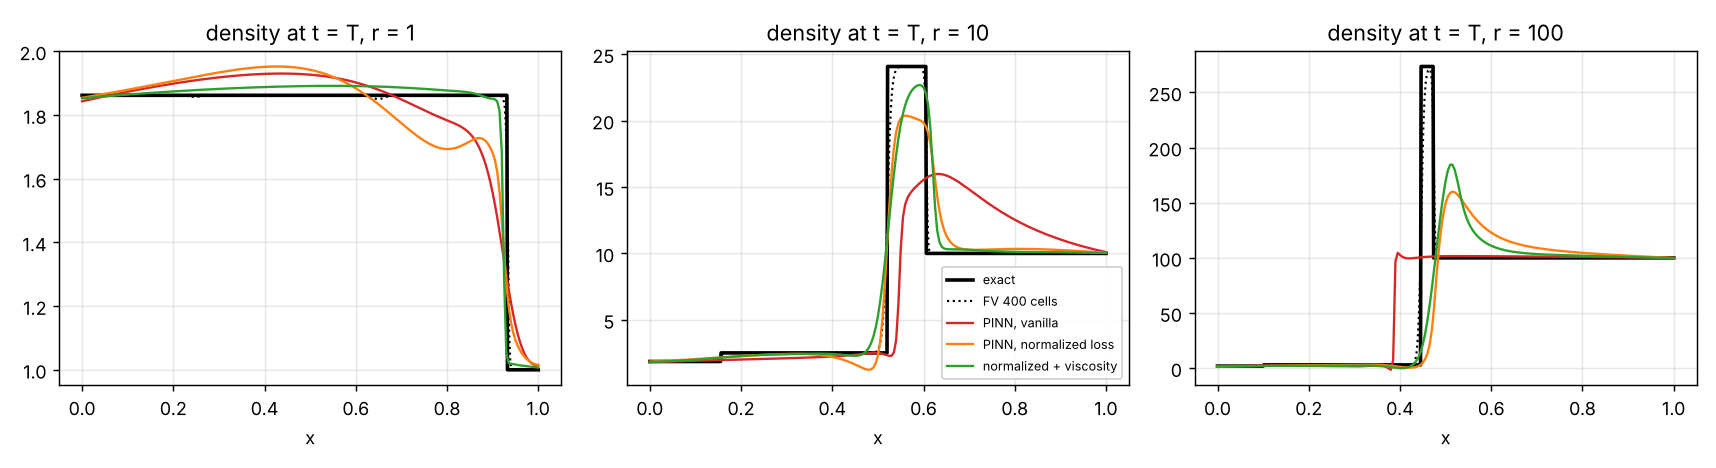

In [10]:
mf.fig_profiles(["vanilla", "normalized", "visc"], tag="fig6_profiles")
display(Image("../figures/fig6_profiles.png"))

At $r = 100$ the vanilla PINN (red) leaves the heavy gas sitting at its initial density and puts no shocked layer there at all. The interface barely moves (we measure it at $x = 0.39$; the exact position at $t=T$ is $0.446$, and it started at $0.40$). Because that missing layer is thin, ignoring it entirely is "cheap" in $L_2$, cheaper than putting a layer in slightly the wrong place, which is what the normalized PINN (orange) does. So for large $r$ the $L_2$ number on its own undersells how wrong the vanilla answer is. We added two interface-specific measures at $t = T$ (computed below, also saved to `results/interface.csv`):

In [11]:
rows_if = mf.interface_table([n for n in mf.COL])
lab = {"fv": "finite volume, 400 cells", "supervised": "supervised fit", "vanilla": "PINN, vanilla",
       "normalized": "PINN, normalized", "visc": "normalized + viscosity", "rad": "normalized + RAD",
       "logrho": r"normalized + $\log\rho$", "causal": "normalized + causal"}
d = {(m, r): (pe, pk) for m, r, _, _, pe, pk in rows_if}
rows = []
for m in ["fv", "supervised", "vanilla", "normalized", "rad", "logrho", "causal", "visc"]:
    rows.append([lab[m]] + [f"{d[(m, r)][0] + 0.0:+.3f}".replace("-0.000", "0.000").replace("+0.000", "0.000") + " / " + f"{d[(m, r)][1]:.2f}" for r in [10, 100]])
table(["model", "$r=10$: interface position error / peak density fraction",
       "$r=100$: interface position error / peak density fraction"], rows)

| model | $r=10$: interface position error / peak density fraction | $r=100$: interface position error / peak density fraction |
|---|---|---|
| finite volume, 400 cells | -0.004 / 1.00 | -0.005 / 0.99 |
| supervised fit | 0.000 / 1.00 | +0.004 / 1.00 |
| PINN, vanilla | +0.030 / 0.66 | -0.056 / 0.38 |
| PINN, normalized | 0.000 / 0.85 | +0.024 / 0.58 |
| normalized + RAD | +0.010 / 0.85 | +0.034 / 0.56 |
| normalized + $\log\rho$ | 0.000 / 0.86 | +0.024 / 0.78 |
| normalized + causal | -0.045 / 0.91 | -0.036 / 0.69 |
| normalized + viscosity | -0.005 / 0.94 | +0.009 / 0.67 |


(The PINN fields are saved on a grid with spacing 0.005, so position errors below that are not meaningful. At $r=100$ the vanilla PINN's interface sits at $x=0.39$, i.e. it never moved from where it started.)

### P4: Where is the error?

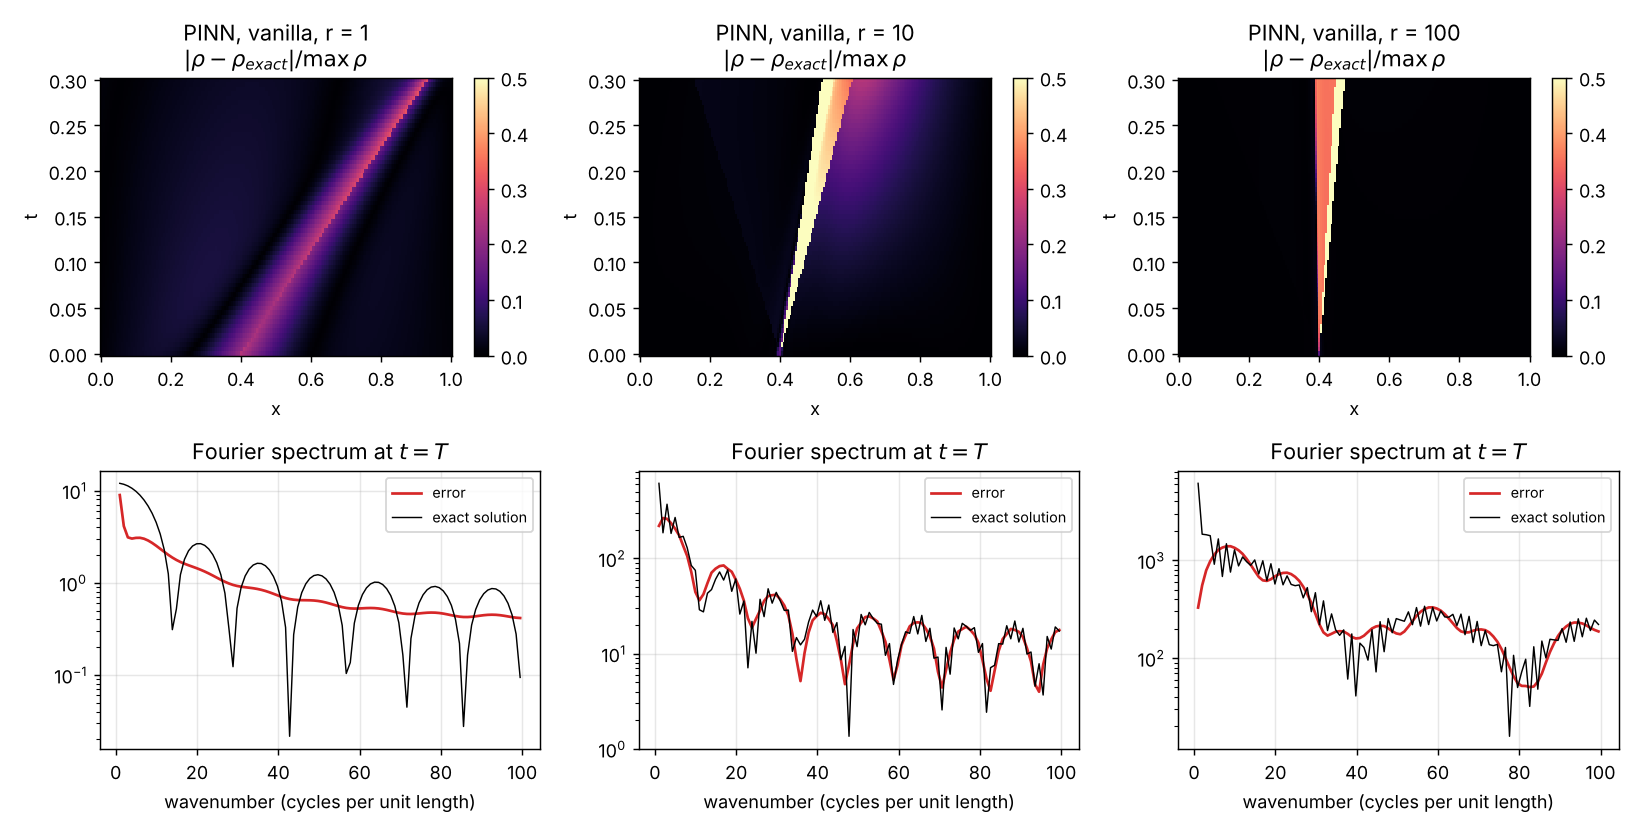

In [12]:
mf.fig_where("vanilla")
display(Image("../figures/fig5_where.png"))

Top: pointwise density error in $(x,t)$ for the vanilla PINN. The error sits on the wave paths and is already there at the earliest times, starting from the point $(x_0, 0)$ where the waves are born. It is not something that builds up late in time, which already makes a causality problem unlikely (we tested it anyway below). At $r = 10$ and $100$ the error fills the whole wedge between the interface and the transmitted shock, i.e. the shocked heavy layer is wrong as a whole.

Bottom: Fourier spectrum of the density error at $t = T$ next to the spectrum of the exact solution. At $r = 1$ the error spectrum is flat-ish and sits below the solution at low wavenumbers: the PINN has the right shape but a smeared shock, which is the classic spectral-bias picture. At $r = 10$ and $r = 100$ the error spectrum lies on top of the solution's own spectrum at nearly all wavenumbers. That means the error is not "missing high frequencies of the right answer", it is a different answer.

### P5: Cost

Hardware: one CPU core of a cloud VM (we ran two jobs side by side on a 2-core machine), no GPU. Times below are read from the run logs.

In [13]:
def times(exps):
    tr = [R[k]["train_time"] for k in R if k[0] in exps]
    inf = [R[k]["infer_time"] for k in R if k[0] in exps]
    rng = lambda a, b, u: f"{a:.0f} {u}" if round(a) == round(b) else f"{a:.0f}–{b:.0f} {u}"
    return rng(min(tr) / 60, max(tr) / 60, "min"), rng(1e3 * min(inf), 1e3 * max(inf), "ms")

best = lambda exps: min(R[(e, 10, 0)]["err_rho"] for e in exps)
rows = [["finite volume, 400 cells", "none", f"{FV['10']['400']['wall']:.2f} s", f3(FV["10"]["400"]["err_rho"])],
        ["finite volume, 1600 cells", "none", f"{FV['10']['1600']['wall']:.2f} s", f3(FV["10"]["1600"]["err_rho"])]]
for label, exps in [("PINN (vanilla / normalized / RAD / log rho)", ["vanilla", "normalized", "rad", "logrho"]),
                    ("PINN + viscosity (second derivatives)", ["visc"]),
                    ("PINN + causal weights", ["causal"])]:
    rows.append([label, *times(exps), f3(best(exps))])
table(["method", "training", "one solve / inference on the 201×61 grid", r"best $\rho$ error at $r=10$"], rows)

T_train = np.median([R[k]["train_time"] for k in R if k[0] == "vanilla"])
T_sol = FV["10"]["400"]["wall"]
T_inf = np.median([R[k]["infer_time"] for k in R if k[0] == "vanilla"])
print(f"T_train ~ {T_train:.0f} s, T_sol (FV, 400 cells) ~ {T_sol:.2f} s, T_inf ~ {1e3*T_inf:.0f} ms")
print(f"If each new case needs retraining: T_sol - T_train = {T_sol - T_train:.0f} s < 0  ->  no break-even")
print(f"Counting only re-evaluation of one trained network: N* = T_train/(T_sol - T_inf) = {T_train/(T_sol - T_inf):.0f}")

| method | training | one solve / inference on the 201×61 grid | best $\rho$ error at $r=10$ |
|---|---|---|---|
| finite volume, 400 cells | none | 0.19 s | 0.101 |
| finite volume, 1600 cells | none | 1.39 s | 0.060 |
| PINN (vanilla / normalized / RAD / log rho) | 9–12 min | 5–11 ms | 0.216 |
| PINN + viscosity (second derivatives) | 24 min | 5 ms | 0.208 |
| PINN + causal weights | 14–16 min | 6–9 ms | 0.225 |


T_train ~ 551 s, T_sol (FV, 400 cells) ~ 0.19 s, T_inf ~ 8 ms
If each new case needs retraining: T_sol - T_train = -551 s < 0  ->  no break-even
Counting only re-evaluation of one trained network: N* = T_train/(T_sol - T_inf) = 2996


*Break-even $N^\star$.* A PINN solves one instance. Every new density ratio, shock strength or initial interface position is a new training run, so the cost per query is the training cost, $T_{\text{inf}} \approx T_{\text{train}} \approx 600$ s against $T_{\text{sol}} = 0.2$ s. $T_{\text{sol}} - T_{\text{inf}} < 0$, so there is no break-even: $N^\star$ does not exist. Even if we only count re-evaluating the same trained network (5 ms vs 0.2 s), $N^\star = 600/0.195 \approx 3000$ evaluations of a solution we already know, at worse accuracy than the solver it replaces. A PINO trained over a family of $r$ values would be the only way to get a real $N^\star$, and given the single-instance results we do not expect it to reach useful accuracy either.

### Path B: Diagnosis

We reproduced the failure we expected from the triage guide and watched it get worse with the knob (P3). Then we tested one candidate explanation at a time, changing a single thing relative to a reference run each time.

**1. Can the network even represent the answer? (expressivity vs. optimization)** We trained the exact same network by plain regression on the exact solution at the collocation points. It reaches 0.7%, 5.8% and 7.7% error at $r = 1, 10, 100$, i.e. better than the 400-cell FV solver at every $r$, with the interface within 0.004 of the right place and the full peak density at $r=100$. So a smooth tanh network with 4×64 units can hold this solution, and the failure is in the physics-informed loss, not in the network (this is the Krishnapriyan et al. test).

**2. Loss imbalance.** Dividing each loss term by a typical size of its variable (IC/BC) or equation (residuals) is the only change between "vanilla" and "normalized". At $r = 10$ the error drops from 36% to 22%. At $r = 100$ the qualitative failure changes: the vanilla PINN never forms the shocked layer, the normalized one does (peak density 38% → 58% of exact, interface position error −0.056 → +0.024). Imbalance is a real cause at large $r$, and it gets worse with the knob because the IC/BC terms scale like $r^2$ in raw units. But fixing it still leaves 22–38% error, so it is not the whole story.

**3. Sampling / resolution.** Residual-based adaptive resampling (RAD: every 1000 iterations, redraw the 4000 points with probability proportional to the residual) on top of the normalized loss: 7.7%, 27% and 39% at $r = 1, 10, 100$, slightly *worse* than without it. The points did move toward the fronts, though only moderately: at the end about 24% of them sit within 0.03 of a wave path, against 15% for uniform sampling (the scheme keeps a uniform floor on purpose). A more aggressive scheme might do more, but there is a cleaner argument: the supervised fit in test 1 used exactly the same 4000 uniformly drawn points and got 6% error at $r=10$. Point count and placement are not what is limiting the PINN.

In [14]:
# How far did adaptive sampling actually move the collocation points toward the fronts?
from riemann import wave_summary
rng = np.random.default_rng(0)
for r in [10, 100]:
    d = np.load(f"../results/runs/rad_r{r}_s0.npz"); x, t = d["x_r"].ravel(), d["t_r"].ravel()
    w = wave_summary(r)
    near = lambda x, t: np.min(np.abs(np.stack([x - (X0 + w[k] * t) for k in
                          ["reflected_speed", "interface_speed", "transmitted_speed"]])), 0) < 0.03
    xu, tu = rng.random(200000), T_END * rng.random(200000)
    print(f"r = {r}: fraction of points within 0.03 of a wave path: RAD {near(x, t).mean():.2f}, uniform {near(xu, tu).mean():.2f}")

r = 10: fraction of points within 0.03 of a wave path: RAD 0.24, uniform 0.15
r = 100: fraction of points within 0.03 of a wave path: RAD 0.20, uniform 0.13


**4. Output dynamic range.** At $r = 100$ density spans 1.9 to 273, so in the scaled output the light gas is a small number. Predicting $\log\rho$ instead: 22% and 39% at $r = 10, 100$, no change. Not the cause.

**5. Causality.** Causal weighting (Wang, Sankaran & Perdikaris, 2024) with 16 time bins and $\epsilon = 50$. The smallest bin weight stayed at 0.00 for the whole run at both $r = 10$ and $r = 100$: the loss in the earliest time bin never gets small enough for later times to switch on. That is the same symptom as the IC plateau in P2: the trouble is at $t \to 0^+$, where all three waves come out of one point and the gradients are unbounded. The error ended up about where it was (22%, 36%). Combined with P4 (the error is there from the first time step, not accumulated), we rule out causality as the main mechanism.

In [15]:
for r in [10, 100]:
    h = R[("causal", r, 0)]["hist"]
    print(f"r = {r}: smallest causal bin weight over training: max {max(h['wmin']):.2e}, final {h['wmin'][-1]:.2e}")

r = 10: smallest causal bin weight over training: max 0.00e+00, final 0.00e+00
r = 100: smallest causal bin weight over training: max 0.00e+00, final 0.00e+00


**6. Regularity of the target.** The exact solution is a weak solution with three jumps. In the strong-form residual we minimize, $\partial_t U + \partial_x F(U)$ is a delta function at a jump, so the loss has no finite minimizer at the true solution. Any smooth network that approximates a jump has a huge residual concentrated in a thin region, and gradient descent makes that cheaper by spreading the jump out, which is exactly the smeared and shifted profiles we see. If this is the mechanism, giving the PDE a smooth solution should help. We added an artificial viscosity term $\nu\,\partial_{xx}U$ to all three residuals, starting at $\nu = 5\times10^{-3}$ and decaying to $10^{-3}$ over 80% of training. Result: 3.1% at $r = 1$ (from 7.3%), 21% at $r = 10$ (from 22%), 35% at $r = 100$ (from 38%). The IC loss finally drops below the plateau, to about $2\times10^{-3}$ at $r=1$ (P2).

In [16]:
# Smearing of a contact by the final viscosity vs the width of the shocked heavy layer at t = T
nu_final = EXPERIMENTS["visc"]["nu_final"]
print(f"sqrt(nu*T) = {np.sqrt(nu_final * T_END):.3f}")
for r in [3, 10, 30, 100]:
    w = wave_summary(r)
    print(f"r = {r:>3}: shocked heavy layer width at t = T = {(w['transmitted_speed'] - w['interface_speed']) * T_END:.3f}")

sqrt(nu*T) = 0.017
r =   3: shocked heavy layer width at t = T = 0.159
r =  10: shocked heavy layer width at t = T = 0.085
r =  30: shocked heavy layer width at t = T = 0.049
r = 100: shocked heavy layer width at t = T = 0.027


So viscosity fixes the shock and barely touches the interface. The reason is the physics of the two kinds of jump. A shock is self-steepening: with viscosity it becomes a thin profile of width about $\nu/\Delta u$, around $10^{-3}$ here, so the viscous solution stays close to the inviscid one. A contact is not: viscosity smears it like diffusion, to a width of about $\sqrt{\nu t} \approx \sqrt{10^{-3}\times0.3} \approx 0.017$ by $t = T$. The shocked heavy layer at $r=100$ is only 0.027 wide (computed in the cell above). In other words, the amount of regularization the PINN needs in order to train is enough to wipe out the feature we care about. The higher the density ratio, the thinner that layer gets (0.085 at $r=10$, 0.027 at $r=100$), which is why the knob hurts.

Putting it together, two problems stack: a loss imbalance that grows like $r^2$ (fixable by scaling the loss), and underneath it a strong-form residual that cannot represent a discontinuity, which can be regularized for shocks but not for a material interface without smearing away the thin high-density layer that the density ratio creates.

### Path C: Fix (partial)

The remedy that targets the diagnosed mechanism is the viscosity curriculum, on top of the loss normalization. Before/after:

|  | $r=1$ | $r=10$ | $r=100$ |
|---|---|---|---|
| vanilla | 0.080 | 0.362 | 0.321 |
| normalized + viscosity curriculum | 0.031 | 0.208 | 0.353 |
| finite volume, 400 cells | 0.016 | 0.101 | 0.122 |


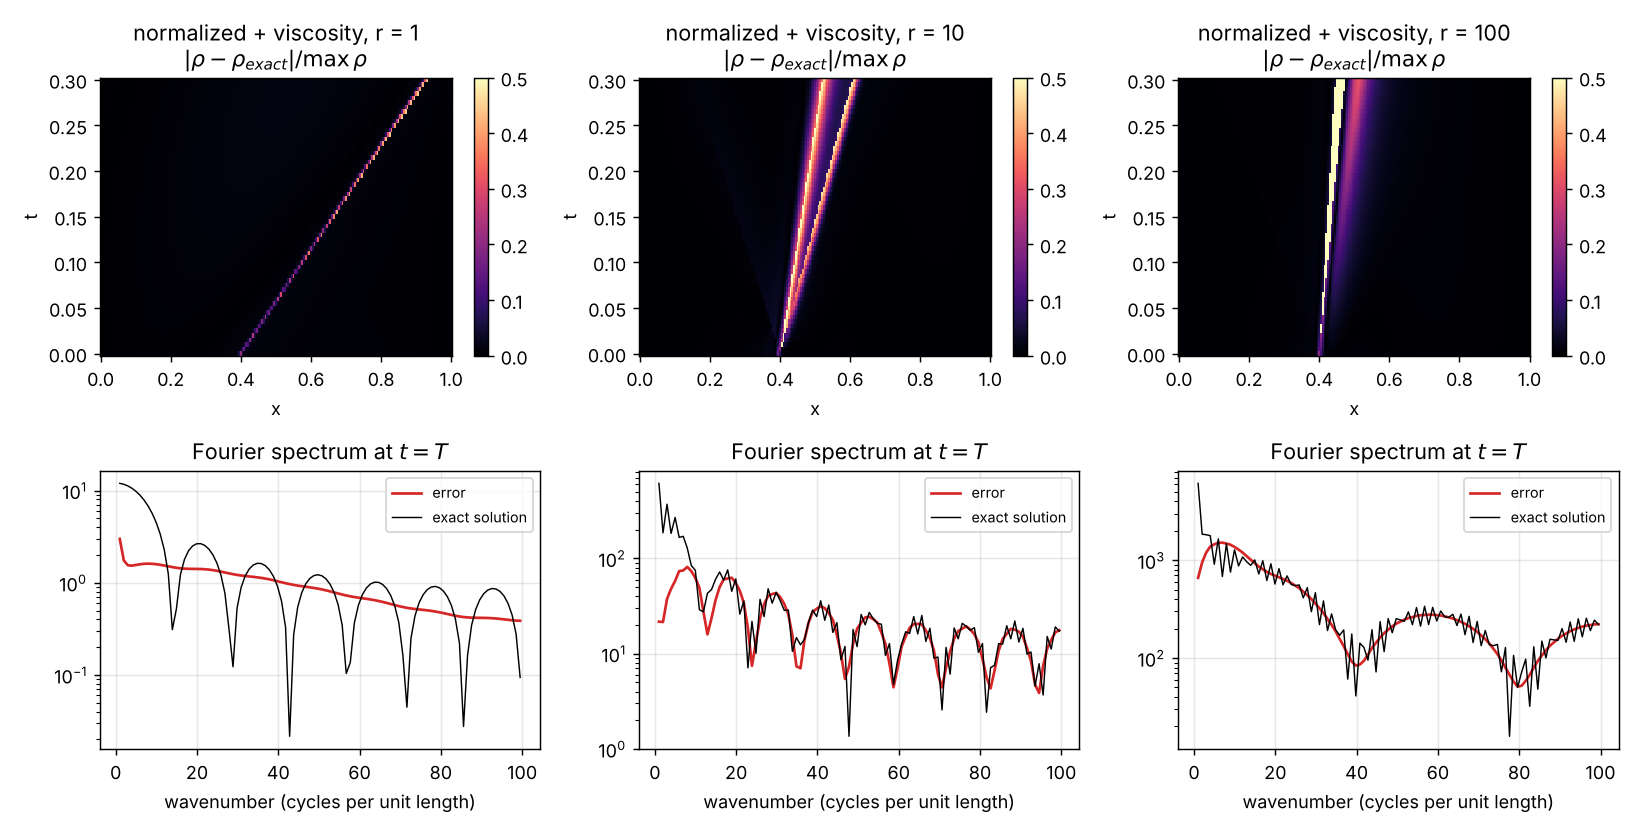

In [17]:
table(["", "$r=1$", "$r=10$", "$r=100$"],
      [["vanilla"] + [f3(R[("vanilla", r, 0)]["err_rho"]) for r in [1, 10, 100]],
       ["normalized + viscosity curriculum"] + [f3(R[("visc", r, 0)]["err_rho"]) for r in [1, 10, 100]],
       ["finite volume, 400 cells"] + [f3(FV[str(r)]["400"]["err_rho"]) for r in [1, 10, 100]]])
mf.fig_where("visc", tag="fig7_where_visc")
display(Image("../figures/fig7_where_visc.png"))

With viscosity the error at $r = 1$ is a thin line along the shock path, with the same structure an FV solver produces. At $r = 10$ the error is now two thin lines (interface and transmitted shock) instead of a filled wedge, so the solution is structurally right and just smeared. At $r = 100$ the layer is still there but smeared to roughly double its width and two thirds of its peak density, as the $\sqrt{\nu t}$ argument predicts.

We call this a partial fix. It works for the shock-only end of the knob and turns a wrong answer into a smeared right one at $r=10$, but it does not solve the case Prof. Herrmann actually cares about (large density ratios), and it costs 2.6× more training time for an answer that is still worse than a 0.03 s finite-volume run. The other variants we tried (adaptive sampling, $\log\rho$ output, causal weights) are kept in the report as negative results because they each rule out an explanation:

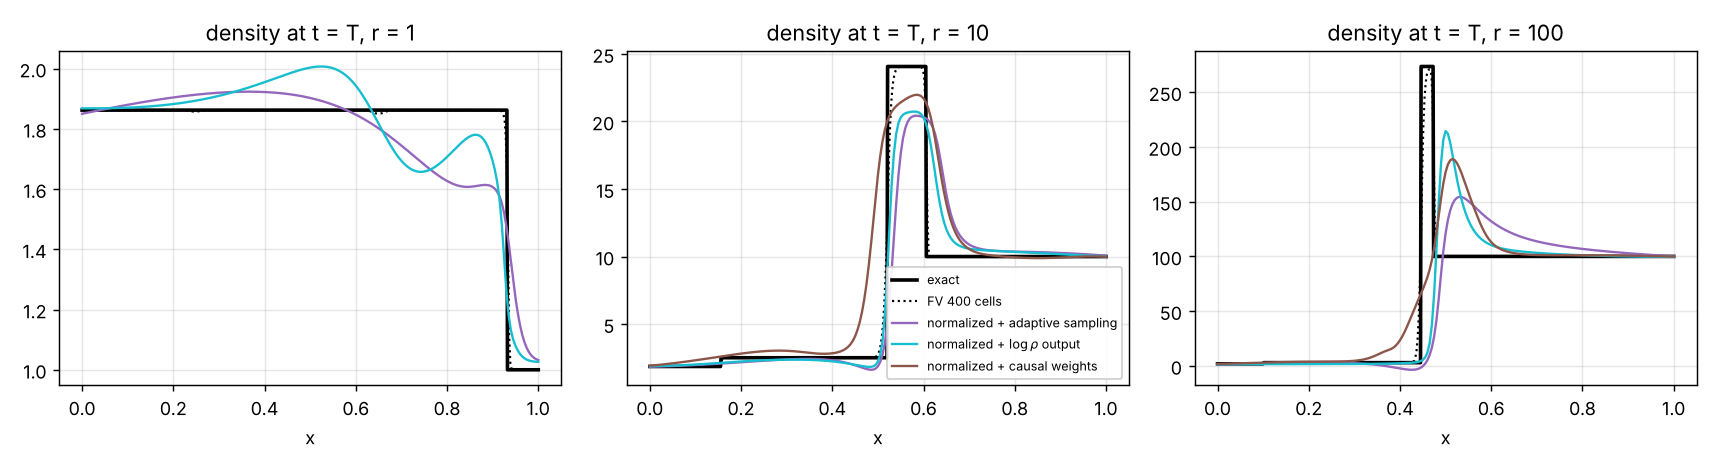

In [18]:
mf.fig_profiles(["rad", "logrho", "causal"], tag="fig8_profiles_other")
display(Image("../figures/fig8_profiles_other.png"))

### Reproducibility check

Every run fixes the PyTorch and NumPy seeds (`seed` in `Config`). To show the stored results are not cherry-picked, the cell below retrains one case from scratch (vanilla PINN, $r = 10$, seed 0; about 10 minutes on one CPU core) and compares it with the stored run. Set `RERUN_ONE = False` at the top to skip it.

In [19]:
if RERUN_ONE:
    new = train(Config(name="vanilla", r=10, seed=0, iters=10000, **EXPERIMENTS["vanilla"]),
                outdir="../results/rerun", verbose=False)
    old = R[("vanilla", 10, 0)]
    for k in ["err_rho", "err_u", "err_p"]:
        print(f"{k}: stored {old[k]:.6f}   rerun {new[k]:.6f}")
    print(f"training time this run: {new['train_time']/60:.1f} min")

err_rho: stored 0.361978   rerun 0.361978
err_u: stored 0.419131   rerun 0.419131
err_p: stored 0.284873   rerun 0.284873
training time this run: 9.1 min


On our machine the rerun matched the stored run in every printed digit. On a different PyTorch version or CPU the numbers can drift a little (floating-point summation order is not guaranteed to be the same), but they should agree to two or three digits.

## 5. Recommendation memo

> **To:** Prof. Marcus Herrmann, SEMTE, ASU
> **From:** [team names], MAE 598 Design Optimization
> **Re:** Can physics-informed neural networks handle a shock hitting a material interface? (our class project)
>
> Dear Prof. Herrmann,
>
> Thank you again for your reply in [month]. We took your advice and dropped the incompressible 1-D level-set case. Instead we did a minimal version of the planar shock/drop interaction you suggested: a Mach 1.5 shock reaching a single planar interface between a light and a heavy ideal gas, in 1-D, starting at the moment of impact. We swept the density ratio from 1 to 100 and compared a physics-informed neural network (PINN) to the exact Riemann solution and to a basic second-order finite-volume code.
>
> **What we found.** The PINN gets worse quickly as the density ratio grows: about 8% density error with no density jump, 36% at a ratio of 10. At a ratio of 100 the plain PINN does not form the thin shocked layer of heavy gas at all. A finite-volume run with only 100 cells, taking 0.03 s, matches or beats every PINN variant we tried at every ratio, and each PINN run took 10 to 25 minutes to train for a single case.
>
> **Why.** The same network fit directly to the exact solution is accurate (0.7–7.7%), so the network can represent sharp interfaces; the problem is training it through the PDE residual. We tested several explanations one at a time. Part of it is loss imbalance that grows with density ratio (fixable by scaling). The rest is that the residual of the strong-form equations is not defined at a discontinuity. Adding artificial viscosity rescues the shock (error 8% → 3%) but cannot rescue the interface, because the viscosity the PINN needs smears a contact by about $\sqrt{\nu t}$, which is about as wide as the shocked layer at a ratio of 100. Collocation-point refinement, a log-density output and causal time weighting did not help.
>
> **How confident are we.** Fairly confident about the direction, less about the exact numbers. Most runs use a single seed and one network size, and we did not try weak-form or finite-volume-style PINN losses, which are the obvious next thing for discontinuous solutions. Our case also uses ideal gases on both sides; a real liquid would make the density ratio about 1000, which by our trend would make things worse, not better.
>
> **Recommendation.** We would not recommend investing in PINNs as forward solvers for your interface problems. The triage guide in our course puts sharp interfaces in the "poor fit" column, and in this case we could not move it out of that column.
>
> **What we would try next.** The VOF interface reconstruction problem you mentioned looks like a much better fit, and our result points the same way. What failed here was training through a PDE residual; what worked was plain supervised fitting to sharp data. Reconstruction is an inverse problem where the forward map (geometry → volume fractions) is cheap, so you can generate as much paired data as you want and train a network directly on it, possibly with a physics or consistency penalty (reconstructed geometry must reproduce the given volume fractions) instead of a PDE residual. A minimal start would be 2-D: a 3×3 stencil of volume fractions in, interface normal and offset out, compared against an existing PLIC/ELVIRA-type reconstruction on circles and perturbed shapes.
>
> Our code and full report are at [repository link]. We would be glad to hear where our setup does not match your experience.
>
> Thank you for your time,
> [names]

[Prof. Herrmann's response, if any:]

## 6. Assumptions and limitations

- **One interface, not a drop.** A 1-D drop has two interfaces and the reflected waves inside it interact. We expect that to be harder for the PINN, not easier, since there are more jumps and they are closer together, but we did not test it.
- **Ideal gas on both sides, same $\gamma$.** A liquid needs a stiffened-gas EOS and a density ratio near 1000. A $\gamma$ jump also brings its own interface problems (pressure oscillations in conservative FV schemes). It might make the comparison less one-sided, because the FV baseline would need more care too.
- **No surface tension, no viscosity, no phase change.** In 1-D planar geometry surface tension does nothing, but in the multi-dimensional problems Prof. Herrmann works on it is a central part of the interface physics.
- **Inviscid exact solution as the reference.** In the viscosity runs the PINN solves a slightly different PDE. We still score against the inviscid answer, since that is what matters for the application.
- **Limited tuning and seeds.** One architecture, one optimizer schedule (Adam only, no L-BFGS), 10,000 iterations, mostly one seed. Bigger networks, longer training or L-BFGS would probably lower the error at $r = 1$. We doubt they change the trend with $r$, because the supervised fit shows capacity is not the limit, but we did not prove that.
- **Strong-form loss only.** Weak/variational PINNs, conservative or finite-volume-style residuals (e.g. "PINNs-WE" with gradient-weighted residuals), and discontinuity-aware architectures are designed for exactly this failure. Our conclusion is about the standard PINN formulation.
- **Verification, not validation.** As Prof. Herrmann pointed out, comparing against an exact or numerical solution verifies the method; it says nothing about agreement with experiments.
- **Metric.** Relative $L_2$ over $(x,t)$ treats a missing thin layer as cheaper than a misplaced one (section P3). We added interface position and peak density to cover that, but no single number captures everything.

## 7. Reproducibility

**Quick start.** `pip install -r requirements.txt` (numpy, scipy, matplotlib, torch; a CPU is enough), then open `report.ipynb` and run all cells. With the default switches it rebuilds the baseline, every table and every figure from the stored runs in a couple of minutes, plus about 10 minutes for the from-scratch reproducibility check. On Colab, put your repo URL in the first code cell.

**Retraining everything.** Set `RUN_ALL_PINNS = True` in the first code cell (about 5 CPU-hours), or run the experiments from a terminal, which is what we did (two at a time on a 2-core machine):

```bash
cd src
for r in 1 3 10 30 100; do python run.py vanilla $r; done
for e in supervised normalized rad visc logrho; do for r in 1 10 100; do python run.py $e $r; done; done
for r in 10 100; do python run.py causal $r; done
for r in 1 10 100; do python run.py vanilla $r 1; done   # second seed
python make_figures.py
```

Each run writes its config, loss history, errors and timings to `results/runs/<experiment>_r<r>_s<seed>.json`, and the predicted fields to a matching `.npz`.

| file | what it does |
|---|---|
| `report.ipynb` | this report |
| `src/riemann.py` | problem setup and exact two-material Riemann solver |
| `src/fv_solver.py` | MUSCL–HLLC finite-volume baseline |
| `src/pinn.py` | PINN, all options in one `Config` dataclass |
| `src/run.py` | named experiments (command line) |
| `src/check_reference.py` | independent checks of the reference and one PINN error |
| `src/make_figures.py` | figures and summary tables |

## References

1. Herrmann, M. (2008). A balanced force refined level set grid method for two-phase flows on unstructured flow solver grids. *Journal of Computational Physics*, 227(4), 2674–2706.
2. Toro, E. F. (2009). *Riemann Solvers and Numerical Methods for Fluid Dynamics* (3rd ed.). Springer. (exact Riemann solver, ch. 4; HLLC, ch. 10)
3. Krishnapriyan, A. S., Gholami, A., Zhe, S., Kirby, R. M., & Mahoney, M. W. (2021). Characterizing possible failure modes in physics-informed neural networks. *NeurIPS 2021*.
4. Wang, S., Yu, X., & Perdikaris, P. (2022). When and why PINNs fail to train: A neural tangent kernel perspective. *Journal of Computational Physics*, 449, 110768.
5. Wang, S., Sankaran, S., & Perdikaris, P. (2024). Respecting causality for training physics-informed neural networks. *Computer Methods in Applied Mechanics and Engineering*, 421, 116813.
6. Wu, C., Zhu, M., Tan, Q., Kartha, Y., & Lu, L. (2023). A comprehensive study of non-adaptive and residual-based adaptive sampling for physics-informed neural networks. *Computer Methods in Applied Mechanics and Engineering*, 403, 115671. (RAD)
7. Mao, Z., Jagtap, A. D., & Karniadakis, G. E. (2020). Physics-informed neural networks for high-speed flows. *Computer Methods in Applied Mechanics and Engineering*, 360, 112789.
8. Fuks, O., & Tchelepi, H. A. (2020). Limitations of physics informed machine learning for nonlinear two-phase transport in porous media. *Journal of Machine Learning for Modeling and Computing*, 1(1). (artificial viscosity for PINNs with shocks)
9. Raissi, M., Perdikaris, P., & Karniadakis, G. E. (2019). Physics-informed neural networks. *Journal of Computational Physics*, 378, 686–707.
10. McGreivy, N., & Hakim, A. (2024). Weak baselines and reporting biases lead to overoptimism in machine learning for fluid-related partial differential equations. *Nature Machine Intelligence*, 6, 1256–1269.